# E2 — Semi-supervisão com consistência temporal

Arquitetura vencedora do E1 (DeepLabV3+, trocável em `ARCHS`) em sete cenários, **com os mesmos lotes**
(8 frames rotulados + 8 centrais não rotulados por passo):

| método | perda |
|---|---|
| `supervised` | $\mathcal L_{sup}$ |
| `fixmatch` | $\mathcal L_{sup} + \lambda(s)\,\mathcal L_{FM}$ |
| `meanteacher` | $\mathcal L_{sup} + \lambda_{MT}(s)\,\mathcal L_{MT}$ |
| `mt-temporal-prev` | $+\ \lambda_{temp}(s)\,\mathcal L_{temp}$, vizinho $t-1$ transportado para $t$ |
| `mt-temporal-bi` | $+\ \lambda_{temp}(s)\,\mathcal L_{temp}$, vizinhos $t-1$ e $t+1$ transportados para $t$ |
| `mt-temporal-prev3` | $+\ \lambda_{temp}(s)\,\mathcal L_{temp}$, vizinho $t-3$ transportado para $t$ (T=3; compara a distância do vizinho com o `prev`) |
| `dtc-trus` | etapa 2 do DTC-TRUS, **sem GT**: $3\mathcal L_{seg}^{flip} + \mathcal L_{KD} + 2\mathcal L_{con} + 0{,}1\,\mathcal L_{proto}$, professor congelado = best ckpt do `supervised` pareado (etapa 1) |

O alvo de $\mathcal L_{MT}$ e $\mathcal L_{temp}$ é o teacher EMA; o student é a única rede otimizada. O
transporte usa fluxo óptico Farneback (convenção DTC-TRUS) e é ponderado por
$M_{noc}=\exp(-\alpha|I_t-W(I_n)|)$. $\lambda_{temp}$ fica em zero no warm-up e só então começa a sua rampa.

**Regime:** treino final nos 80 pacientes de desenvolvimento (todos os rótulos + todo frame nunca anotado
desses vídeos), checkpoint pela validação fixa (`val/dice_patient`), avaliação única no **teste INCA**
(23 pacientes) e no **UNM** inteiro. Agregação: frames → paciente → média dos pacientes.

Config: `configs/sweep/e2.yaml`; lógica: `src/sweeps/e2.py`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../../")

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.evaluation import comparison_table, table_to_markdown
from src.sweep import Sweep, submit_sweep, sweep_status, watch_sweep

SWEEP_CONFIG = "configs/sweep/e2.yaml"

# Grade. Trocar a arquitetura aqui NAO edita o YAML: vira `--set axes.arch=[...]` no processo do tmux.
ARCHS = ["deeplabv3plus"]            # qualquer chave de `arch_configs` (unet, fpn, ...)
POLICIES = ["global"]                # ["global", "same_video"] para comparar a origem dos nao rotulados
SEEDS = [42]
REFERENCE_METHOD = "supervised"

OVERRIDES = {"axes.arch": ARCHS, "axes.unlabeled_policy": POLICIES, "axes.seed": SEEDS}
sweep = Sweep(SWEEP_CONFIG, overrides=OVERRIDES)
sweep.plan_summary()

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


,run_id,seed,arch,unlabeled_policy,method,status
0,deeplabv3plus-supervised-global-s42,42,deeplabv3plus,global,supervised,done (na CSV)
1,deeplabv3plus-fixmatch-global-s42,42,deeplabv3plus,global,fixmatch,done (na CSV)
2,deeplabv3plus-meanteacher-global-s42,42,deeplabv3plus,global,meanteacher,done (na CSV)
3,deeplabv3plus-mt-temporal-prev-global-s42,42,deeplabv3plus,global,mt-temporal-prev,done (na CSV)
4,deeplabv3plus-mt-temporal-bi-global-s42,42,deeplabv3plus,global,mt-temporal-bi,done (na CSV)
5,deeplabv3plus-mt-temporal-prev3-global-s42,42,deeplabv3plus,global,mt-temporal-prev3,done (na CSV)


## Execução

O treino roda numa sessão tmux (`e2`); fechar o notebook não o interrompe.

In [3]:
sweep_status(SWEEP_CONFIG, overrides=OVERRIDES)

,run_id,seed,arch,unlabeled_policy,method,status
0,deeplabv3plus-supervised-global-s42,42,deeplabv3plus,global,supervised,done (na CSV)
1,deeplabv3plus-fixmatch-global-s42,42,deeplabv3plus,global,fixmatch,done (na CSV)
2,deeplabv3plus-meanteacher-global-s42,42,deeplabv3plus,global,meanteacher,done (na CSV)
3,deeplabv3plus-mt-temporal-prev-global-s42,42,deeplabv3plus,global,mt-temporal-prev,done (na CSV)
4,deeplabv3plus-mt-temporal-bi-global-s42,42,deeplabv3plus,global,mt-temporal-bi,done (na CSV)
5,deeplabv3plus-mt-temporal-prev3-global-s42,42,deeplabv3plus,global,mt-temporal-prev3,done (na CSV)


In [4]:
# submit_sweep(SWEEP_CONFIG, overrides=OVERRIDES)
watch_sweep(SWEEP_CONFIG, overrides=OVERRIDES)

e2: 6/6 celulas concluidas (19:48:00)
                                    run_id  seed          arch unlabeled_policy            method        status
       deeplabv3plus-supervised-global-s42    42 deeplabv3plus           global        supervised done (na CSV)
         deeplabv3plus-fixmatch-global-s42    42 deeplabv3plus           global          fixmatch done (na CSV)
      deeplabv3plus-meanteacher-global-s42    42 deeplabv3plus           global       meanteacher done (na CSV)
 deeplabv3plus-mt-temporal-prev-global-s42    42 deeplabv3plus           global  mt-temporal-prev done (na CSV)
   deeplabv3plus-mt-temporal-bi-global-s42    42 deeplabv3plus           global    mt-temporal-bi done (na CSV)
deeplabv3plus-mt-temporal-prev3-global-s42    42 deeplabv3plus           global mt-temporal-prev3 done (na CSV)

--- console ---
grade e2: 100%|##########| 6/6 [2:13:19<00:00, 1333.33s/cell]

Concluido. 6 celulas treinadas nesta sessao.

Grade completa.


## Resultados por frame e custo por run

In [5]:
results = sweep.load_results()
resources = sweep.plan.load_resources()
results = results[results.arch.isin(ARCHS) & results.unlabeled_policy.isin(POLICIES) & results.seed.isin(SEEDS)]
resources = resources[resources.arch.isin(ARCHS) & resources.unlabeled_policy.isin(POLICIES) & resources.seed.isin(SEEDS)]
assert set(results.eval_set) <= {"inca_test", "unm"}
results.groupby(["arch", "unlabeled_policy", "method", "eval_set"]).size().unstack()

eval_set                                          inca_test  unm
arch          unlabeled_policy method                           
deeplabv3plus global           fixmatch                 239  325
                               meanteacher              239  325
                               mt-temporal-bi           239  325
                               mt-temporal-prev         239  325
                               mt-temporal-prev3        239  325
                               supervised               239  325

## Tabela comparativa

Acurácia no teste INCA e no UNM (média por paciente; `±` = desvio entre pacientes com uma seed, entre seeds
com várias), diferença **pareada por paciente** contra o supervisionado, e custo: tempo total de parede,
s/passo, fração do treino esperando o DataLoader (fluxo óptico nos workers), pico de VRAM (alocado) no
treino e na inferência, parâmetros do student e do teacher, GFLOPs por frame a 256×256, latência de
inferência, imagens por passo em cada rede, tamanho do checkpoint e passo do melhor checkpoint.

In [6]:
results

,run_id,video_frame,video_id,paciente_id,class,dice,iou,assd,hd95,eval_set,lr,weight_decay,seed,arch,unlabeled_policy,method,output_dir
0,deeplabv3plus-supervised-global-s42,v100_f10,100,115,FG,0.917599,0.847744,1.572037,10.456803,inca_test,0.000299,0.000004,42,deeplabv3plus,global,supervised,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
1,deeplabv3plus-supervised-global-s42,v100_f12,100,115,FG,0.915110,0.843504,1.610672,10.770329,inca_test,0.000299,0.000004,42,deeplabv3plus,global,supervised,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
2,deeplabv3plus-supervised-global-s42,v100_f13,100,115,FG,0.908858,0.832942,1.666221,11.268897,inca_test,0.000299,0.000004,42,deeplabv3plus,global,supervised,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
3,deeplabv3plus-supervised-global-s42,v100_f14,100,115,FG,0.904544,0.825723,1.666965,10.138770,inca_test,0.000299,0.000004,42,deeplabv3plus,global,supervised,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
4,deeplabv3plus-supervised-global-s42,v100_f15,100,115,FG,0.926169,0.862490,1.436821,10.202917,inca_test,0.000299,0.000004,42,deeplabv3plus,global,supervised,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3379,deeplabv3plus-mt-temporal-prev3-global-s42,v090_f1282,90,UNM-090,FG,0.864557,0.761427,1.072368,3.162278,unm,0.000299,0.000004,42,deeplabv3plus,global,mt-temporal-prev3,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
3380,deeplabv3plus-mt-temporal-prev3-global-s42,v090_f1389,90,UNM-090,FG,0.776588,0.634772,1.980160,10.295630,unm,0.000299,0.000004,42,deeplabv3plus,global,mt-temporal-prev3,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
3381,deeplabv3plus-mt-temporal-prev3-global-s42,v090_f1390,90,UNM-090,FG,0.742225,0.590110,2.285769,12.836773,unm,0.000299,0.000004,42,deeplabv3plus,global,mt-temporal-prev3,/data_ssd/caioseda/projetos/vfss-seg-benchmark...
3382,deeplabv3plus-mt-temporal-prev3-global-s42,v090_f858,90,UNM-090,FG,0.665710,0.498925,2.395844,12.121718,unm,0.000299,0.000004,42,deeplabv3plus,global,mt-temporal-prev3,/data_ssd/caioseda/projetos/vfss-seg-benchmark...


In [7]:
BY = ["arch", "unlabeled_policy", "method"]
table = comparison_table(results, resources, by=BY, reference=REFERENCE_METHOD)
METHOD_ORDER = ["supervised", "fixmatch", "meanteacher", "mt-temporal-prev", "mt-temporal-prev3", "mt-temporal-bi", "dtc-trus"]
table["method"] = pd.Categorical(table["method"], METHOD_ORDER, ordered=True)
table = table.sort_values(BY).reset_index(drop=True)

out_dir = Path(sweep.family_dir)
table.to_csv(out_dir / "comparison_table.csv", index=False)
(out_dir / "comparison_table.md").write_text(table_to_markdown(table))
pd.set_option("display.max_columns", None)
table.round(4)

,arch,unlabeled_policy,method,inca_test dice,inca_test ± dice,inca_test iou,inca_test ± iou,inca_test assd,inca_test ± assd,inca_test hd95,inca_test ± hd95,unm dice,unm ± dice,unm iou,unm ± iou,unm assd,unm ± assd,unm hd95,unm ± hd95,± entre,tempo total (h),s/passo,espera por dados (%),VRAM treino (GB),VRAM inferência (GB),params student (M),params teacher (M),params treináveis (M),GFLOPs/frame,latência bs1 (ms/frame),latência bs8 (ms/frame),imagens/passo student,imagens/passo teacher,checkpoint (MB),passo do melhor ckpt
0,deeplabv3plus,global,supervised,0.8670,0.0494,0.7696,0.0715,1.3651,0.6357,5.8906,4.1983,0.7925,0.0589,0.6640,0.0763,6.7600,6.9100,33.8031,32.0145,pacientes,0.2323,0.1144,42.5488,1.5969,1.2789,22.4377,0.0000,22.4377,15.7701,4.7035,0.6006,16.0000,NaN,257.1506,6500.0
1,deeplabv3plus,global,fixmatch,0.8705,0.0383,0.7739,0.0574,1.3023,0.4534,5.4877,3.2490,0.8109,0.0506,0.6891,0.0661,1.7178,0.7624,6.2984,4.4165,pacientes,0.1994,0.1438,16.2755,2.2288,1.2520,22.4377,0.0000,22.4377,15.7701,4.7611,0.6031,23.5253,NaN,257.1335,4500.0
2,deeplabv3plus,global,meanteacher,0.8759,0.0402,0.7827,0.0606,1.2075,0.4731,5.0818,2.9972,0.8089,0.0646,0.6876,0.0853,3.8437,5.9282,16.2851,26.6811,pacientes,0.0948,0.1164,32.2356,1.8751,1.3376,22.4377,22.4377,22.4377,15.7701,4.8138,0.6049,16.0000,7.1456,342.8880,2500.0
3,deeplabv3plus,global,mt-temporal-prev,0.8723,0.0465,0.7777,0.0697,1.2086,0.5274,4.8122,3.7305,0.8225,0.0487,0.7045,0.0653,1.5663,0.8026,5.8308,4.4504,pacientes,0.0961,0.1533,40.3886,2.1972,1.3376,22.4377,22.4377,22.4377,15.7701,4.7169,0.5903,16.0000,13.8345,342.8840,2000.0
4,deeplabv3plus,global,mt-temporal-prev3,0.8763,0.0397,0.7835,0.0603,1.1745,0.4183,4.6701,2.7678,0.8091,0.0510,0.6866,0.0676,3.2623,3.4104,16.1762,20.0779,pacientes,0.1481,0.1572,42.7684,2.0252,1.3376,22.4377,22.4377,22.4377,15.7701,4.7524,0.5942,16.0000,14.4727,342.8925,3000.0
5,deeplabv3plus,global,mt-temporal-bi,0.8767,0.0425,0.7842,0.0636,1.1906,0.4869,4.7538,2.7672,0.8189,0.0459,0.6985,0.0629,2.1686,1.9876,10.4620,14.4827,pacientes,0.1198,0.1959,53.1713,2.4272,1.3376,22.4377,22.4377,22.4377,15.7701,8.0842,1.0096,16.0000,20.7275,342.8839,2000.0


### Só acurácia (para o texto)

In [8]:
accuracy_cols = BY + [c for c in table.columns if c.startswith(("inca_test", "unm")) and ("dice" in c or "hd95" in c)]
table[accuracy_cols].round(4)

,arch,unlabeled_policy,method,inca_test dice,inca_test ± dice,inca_test hd95,inca_test ± hd95,unm dice,unm ± dice,unm hd95,unm ± hd95
0,deeplabv3plus,global,supervised,0.8670,0.0494,5.8906,4.1983,0.7925,0.0589,33.8031,32.0145
1,deeplabv3plus,global,fixmatch,0.8705,0.0383,5.4877,3.2490,0.8109,0.0506,6.2984,4.4165
2,deeplabv3plus,global,meanteacher,0.8759,0.0402,5.0818,2.9972,0.8089,0.0646,16.2851,26.6811
3,deeplabv3plus,global,mt-temporal-prev,0.8723,0.0465,4.8122,3.7305,0.8225,0.0487,5.8308,4.4504
4,deeplabv3plus,global,mt-temporal-prev3,0.8763,0.0397,4.6701,2.7678,0.8091,0.0510,16.1762,20.0779
5,deeplabv3plus,global,mt-temporal-bi,0.8767,0.0425,4.7538,2.7672,0.8189,0.0459,10.4620,14.4827


### Só custo

In [9]:
cost_cols = BY + [c for c in table.columns if c not in accuracy_cols and not c.startswith(("inca_test", "unm")) and c != "± entre"]
table[cost_cols].round(3)

,arch,unlabeled_policy,method,tempo total (h),s/passo,espera por dados (%),VRAM treino (GB),VRAM inferência (GB),params student (M),params teacher (M),params treináveis (M),GFLOPs/frame,latência bs1 (ms/frame),latência bs8 (ms/frame),imagens/passo student,imagens/passo teacher,checkpoint (MB),passo do melhor ckpt
0,deeplabv3plus,global,supervised,0.232,0.114,42.549,1.597,1.279,22.438,0.000,22.438,15.77,4.703,0.601,16.000,NaN,257.151,6500.0
1,deeplabv3plus,global,fixmatch,0.199,0.144,16.275,2.229,1.252,22.438,0.000,22.438,15.77,4.761,0.603,23.525,NaN,257.134,4500.0
2,deeplabv3plus,global,meanteacher,0.095,0.116,32.236,1.875,1.338,22.438,22.438,22.438,15.77,4.814,0.605,16.000,7.146,342.888,2500.0
3,deeplabv3plus,global,mt-temporal-prev,0.096,0.153,40.389,2.197,1.338,22.438,22.438,22.438,15.77,4.717,0.590,16.000,13.834,342.884,2000.0
4,deeplabv3plus,global,mt-temporal-prev3,0.148,0.157,42.768,2.025,1.338,22.438,22.438,22.438,15.77,4.752,0.594,16.000,14.473,342.893,3000.0
5,deeplabv3plus,global,mt-temporal-bi,0.120,0.196,53.171,2.427,1.338,22.438,22.438,22.438,15.77,8.084,1.010,16.000,20.728,342.884,2000.0


## Curvas de treino: pesos dos termos e perdas não supervisionadas

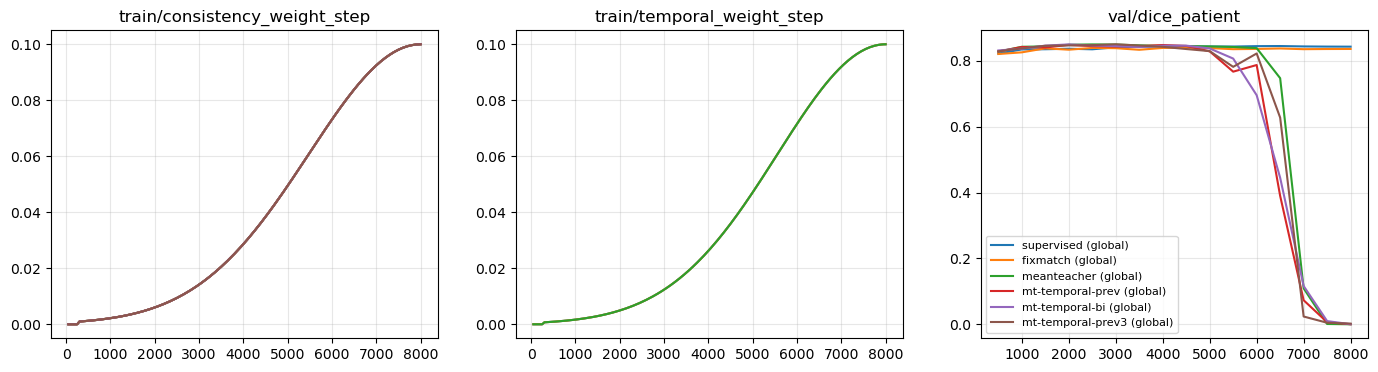

In [11]:
def metrics_of(output_dir):
    path = Path(output_dir) / "csv" / "metrics.csv"
    return pd.read_csv(path) if path.exists() else pd.DataFrame()   # fast_dev_run nao grava CSV

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for _, row in resources.iterrows():
    metrics = metrics_of(row.output_dir)
    label = f"{row.method} ({row.unlabeled_policy})"
    for ax, key in zip(axes, ["train/consistency_weight_step", "train/temporal_weight_step", "val/dice_patient"]):
        if key in metrics:
            series = metrics[["step", key]].dropna() if "step" in metrics else metrics[[key]].dropna()
            ax.plot(series.index if "step" not in series else series["step"], series[key], label=label)
            ax.set_title(key)
axes[-1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)

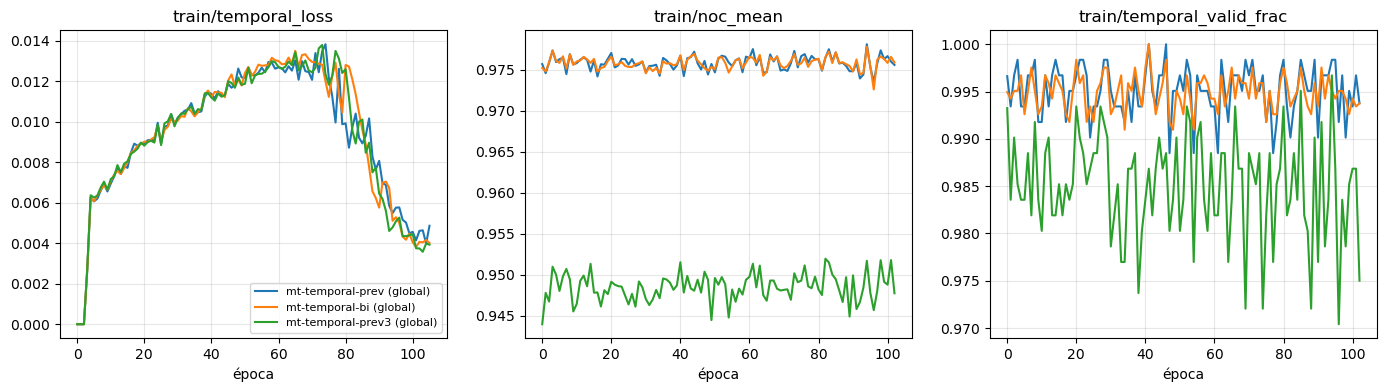

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for _, row in resources[resources.method.astype(str).str.startswith("mt-temporal")].iterrows():
    metrics = metrics_of(row.output_dir)
    for ax, key in zip(axes, ["train/temporal_loss_epoch" if "train/temporal_loss_epoch" in metrics else "train/temporal_loss",
                              "train/noc_mean", "train/temporal_valid_frac"]):
        if key in metrics:
            series = metrics[key].dropna().reset_index(drop=True)
            ax.plot(series, label=f"{row.method} ({row.unlabeled_policy})")
            ax.set_title(key)
for ax in axes:
    ax.grid(alpha=0.3); ax.set_xlabel("época")
axes[0].legend(fontsize=8)

## Por paciente (teste INCA)

In [27]:
per_patient = (results[results.eval_set == "inca_test"]
               .groupby(BY + ["paciente_id"], observed=True).dice.mean().unstack("method"))
per_patient.round(4)

method                                      fixmatch  meanteacher  \
arch          unlabeled_policy paciente_id                          
deeplabv3plus global           1              0.8847       0.8984   
                               10             0.8452       0.8493   
                               115            0.9132       0.9171   
                               12             0.8763       0.8772   
                               16             0.8489       0.8628   
                               20             0.9324       0.9331   
                               26             0.8470       0.8501   
                               27             0.8397       0.8682   
                               34             0.8917       0.9028   
                               42             0.8543       0.8857   
                               52             0.8777       0.9081   
                               56             0.9269       0.9267   
                               61             0.8654       0.8219   
                               63             0.8754       0.8706   
                               67             0.8884       0.8854   
                               69             0.8944       0.9025   
                               82             0.8803       0.9001   
                               85             0.9018       0.9074   
                               86             0.7439       0.7475   
                               88             0.8429       0.8495   
                               96             0.8565       0.8502   
                               97             0.8862       0.8830   
                               99             0.8475       0.8482   

method                                      mt-temporal-bi  mt-temporal-prev  \
arch          unlabeled_policy paciente_id                                     
deeplabv3plus global           1                    0.8975            0.9007   
                               10                   0.8469            0.8489   
                               115                  0.9366            0.9499   
                               12                   0.8770            0.8723   
                               16                   0.8562            0.8283   
                               20                   0.9288            0.9309   
                               26                   0.8510            0.8531   
                               27                   0.8449            0.8533   
                               34                   0.9127            0.8994   
                               42                   0.8812            0.8632   
                               52                   0.9133            0.9076   
                               56                   0.9212            0.9117   
                               61                   0.8453            0.8000   
                               63                   0.8575            0.8753   
                               67                   0.8853            0.8854   
                               69                   0.9045            0.9055   
                               82                   0.8955            0.8959   
                               85                   0.9016            0.9070   
                               86                   0.7316            0.7282   
                               88                   0.8510            0.8449   
                               96                   0.8733            0.8669   
                               97                   0.8901            0.8830   
                               99                   0.8602            0.8510   

method                                      mt-temporal-prev3  supervised  
arch          unlabeled_policy paciente_id                                 
deeplabv3plus global           1                       0.8967      0.8946  
                               10            

## Investigação do colapso da validação nos métodos MT

Nos quatro métodos com teacher EMA (`meanteacher`, `mt-temporal-*`) a `val/dice_patient` fica em ~0,84 até o
passo ~4500 e cai a ~0 no fim; `supervised` e `fixmatch` (sem teacher) ficam estáveis. Esta seção junta o que
os logs **já** dizem sobre isso.

**O que cada curva mede (e por que elas não são diretamente comparáveis):**

| curva | rede | modo | granularidade | dados |
|---|---|---|---|---|
| `train/dice_score` | student | train (BN com estatísticas do lote) | média por época (~75 passos), por frame | linhas rotuladas do lote |
| `val/dice_patient` | **teacher** nos MT, student nos demais | eval (BN com running stats — no MT, **copiados do student** a cada passo) | a cada 500 passos, média por paciente | validação fixa |

Logo, um gap treino–val nos MT mistura três coisas: (i) os pesos pioraram (overfit), (ii) o teacher em eval
mode quebrou (pesos EMA + running stats do student), (iii) diferença de dados. Estes logs **não separam**
(i) de (ii) — o student em eval nunca foi avaliado nessas runs. Isso é o que a sonda da bateria D0 mede (fim da seção).

As perdas de treino só existem como média por época e os pesos (`*_weight_step`) não foram gravados por
passo; por isso as agendas $\lambda(s)$ e o LR são **recalculados analiticamente** a partir dos YAMLs.

In [28]:
import numpy as np
from omegaconf import OmegaConf
from src.models.ssl.base import sigmoid_rampup

MT_METHODS = ["meanteacher", "mt-temporal-prev", "mt-temporal-prev3", "mt-temporal-bi"]
TOTAL_STEPS = 8000
STEPS = np.arange(TOTAL_STEPS + 1)
COLLAPSE_FRAC = 0.5          # "colapso" = primeira val abaixo de 50% do melhor val Dice da run
DROP_ABS = 0.03              # "inicio da queda" = primeira val, depois do maximo, abaixo de max - 0,03


def schedules(method):
    """lambda_MT(s), lambda_temp(s) e LR(s)/LR_0 por passo, a partir do YAML do metodo (mesma logica de src/models/ssl)."""
    cfg = OmegaConf.load(f"../../../configs/experiment/e2/e2-{method}.yaml")
    p = cfg.lit_module.params
    sched = cfg.lr_scheduler.params
    lr0 = float(cfg.optimizer.params.lr)
    lr = sched.eta_min + 0.5 * (lr0 - sched.eta_min) * (1 + np.cos(np.pi * STEPS / sched.T_max))
    out = pd.DataFrame({"step": STEPS, "lr_rel": lr / lr0, "lam_mt": 0.0, "lam_temp": 0.0})
    out.attrs.update(lam_mt_max=0.0, lam_temp_max=0.0)
    if "consistency_weight" in p:     # FixMatch usa a mesma agenda; supervised nao tem
        warm = p.get("consistency_warmup_fraction", 0.0) * TOTAL_STEPS
        ramp = p.get("consistency_rampup_fraction", 1.0) * TOTAL_STEPS
        out["lam_mt"] = [0.0 if s < warm else p.consistency_weight * sigmoid_rampup(s, ramp) for s in STEPS]
        out.attrs["lam_mt_max"] = float(p.consistency_weight)
    if "temporal_weight" in p:
        warm = p.get("temporal_warmup_fraction", 0.0) * TOTAL_STEPS
        ramp_frac = p.get("temporal_rampup_fraction")
        ramp = (TOTAL_STEPS - warm) if ramp_frac is None else ramp_frac * TOTAL_STEPS
        out["lam_temp"] = [0.0 if s < warm else p.temporal_weight * sigmoid_rampup(s - warm, ramp) for s in STEPS]
        out.attrs["lam_temp_max"] = float(p.temporal_weight)
    return out


TRAIN_COLS = ["train/loss", "train/sup_loss", "train/unsup_loss", "train/unsup_loss_weighted",
              "train/temporal_loss", "train/temporal_loss_weighted", "train/dice_score"]
VAL_COLS = ["val/dice_patient", "val/dice_score", "val/loss"]

runs = {}
for _, row in resources.iterrows():
    m = metrics_of(row.output_dir)
    if m.empty:
        continue
    method = str(row.method)
    train = m[["step"] + [c for c in TRAIN_COLS if c in m]].dropna(subset=["train/loss"]).reset_index(drop=True)
    val = m[["step"] + [c for c in VAL_COLS if c in m]].dropna(subset=["val/dice_patient"]).reset_index(drop=True)
    # Dice de treino (media da epoca) interpolado nos passos de val, para o gap no mesmo eixo.
    val["train_dice_at_val"] = np.interp(val.step, train.step, train["train/dice_score"])
    runs[method] = dict(train=train, val=val, sched=schedules(method), best_step=int(row.best_step))

# Sanity check: o total logado deve ser ~ a soma dos termos ponderados (media de lambda*L por epoca).
for method, r in runs.items():
    t = r["train"]
    parts = t["train/sup_loss"] + t.get("train/unsup_loss_weighted", 0) + t.get("train/temporal_loss_weighted", 0)
    print(f"{method:20s} max |loss - soma dos termos| = {np.abs(t['train/loss'] - parts).max():.2e}")

supervised           max |loss - soma dos termos| = 0.00e+00
fixmatch             max |loss - soma dos termos| = 1.51e-08
meanteacher          max |loss - soma dos termos| = 1.48e-08
mt-temporal-prev     max |loss - soma dos termos| = 1.51e-08
mt-temporal-bi       max |loss - soma dos termos| = 1.74e-08
mt-temporal-prev3    max |loss - soma dos termos| = 1.28e-08


In [29]:
def collapse_step(val):
    """Primeiro passo de val, depois do maximo, abaixo de COLLAPSE_FRAC * max (None se nao houver)."""
    i_best = int(val["val/dice_patient"].idxmax())
    best = val["val/dice_patient"].iloc[i_best]
    after = val.iloc[i_best:]
    below = after[after["val/dice_patient"] < COLLAPSE_FRAC * best]
    return int(below.step.iloc[0]) if len(below) else None


def drop_step(val):
    """Primeiro passo de val, depois do maximo, abaixo de max - DROP_ABS (None se nao houver)."""
    i_best = int(val["val/dice_patient"].idxmax())
    after = val.iloc[i_best:]
    below = after[after["val/dice_patient"] < val["val/dice_patient"].iloc[i_best] - DROP_ABS]
    return int(below.step.iloc[0]) if len(below) else None


def method_grid(methods, nrows=None, ncols=3, best_line=True, **kwargs):
    """Um painel por metodo (eixo x = passo), com a linha pontilhada no best ckpt."""
    nrows = nrows or int(np.ceil(len(methods) / ncols))
    kwargs.setdefault("sharex", True)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows), squeeze=False, **kwargs)
    for ax, method in zip(axes.flat, methods):
        ax.set_title(f"{method} (best = {runs[method]['best_step']})")
        if best_line:
            ax.axvline(runs[method]["best_step"], color="k", ls=":", lw=1)
        ax.grid(alpha=0.3, which="both")
    for ax in axes.flat[len(methods):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("passo")
    return fig, axes


order = [m for m in METHOD_ORDER if m in runs]
mt_order = [m for m in order if m in MT_METHODS]

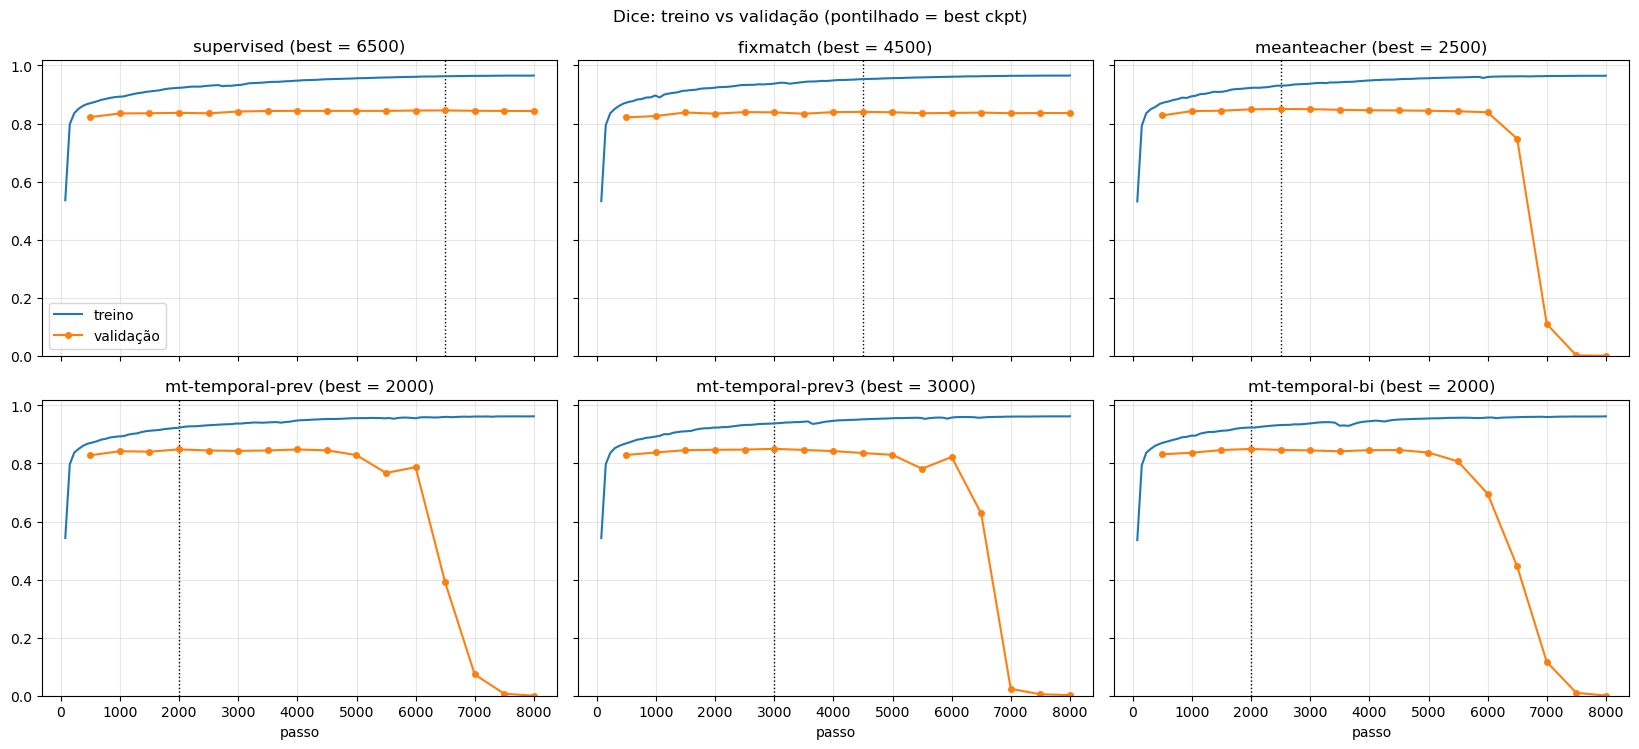

In [30]:
# Dice de treino (student, train mode, media da epoca) vs Dice de validacao (teacher nos MT, eval mode).
fig, axes = method_grid(order, sharey=True)
for ax, method in zip(axes.flat, order):
    t, v = runs[method]["train"], runs[method]["val"]
    ax.plot(t.step, t["train/dice_score"], label="treino")
    ax.plot(v.step, v["val/dice_patient"], "o-", ms=4, label="validação")
    ax.set_ylim(0, 1.02)
axes[0, 0].legend(loc="lower left")
fig.suptitle("Dice: treino vs validação (pontilhado = best ckpt)")
fig.tight_layout()

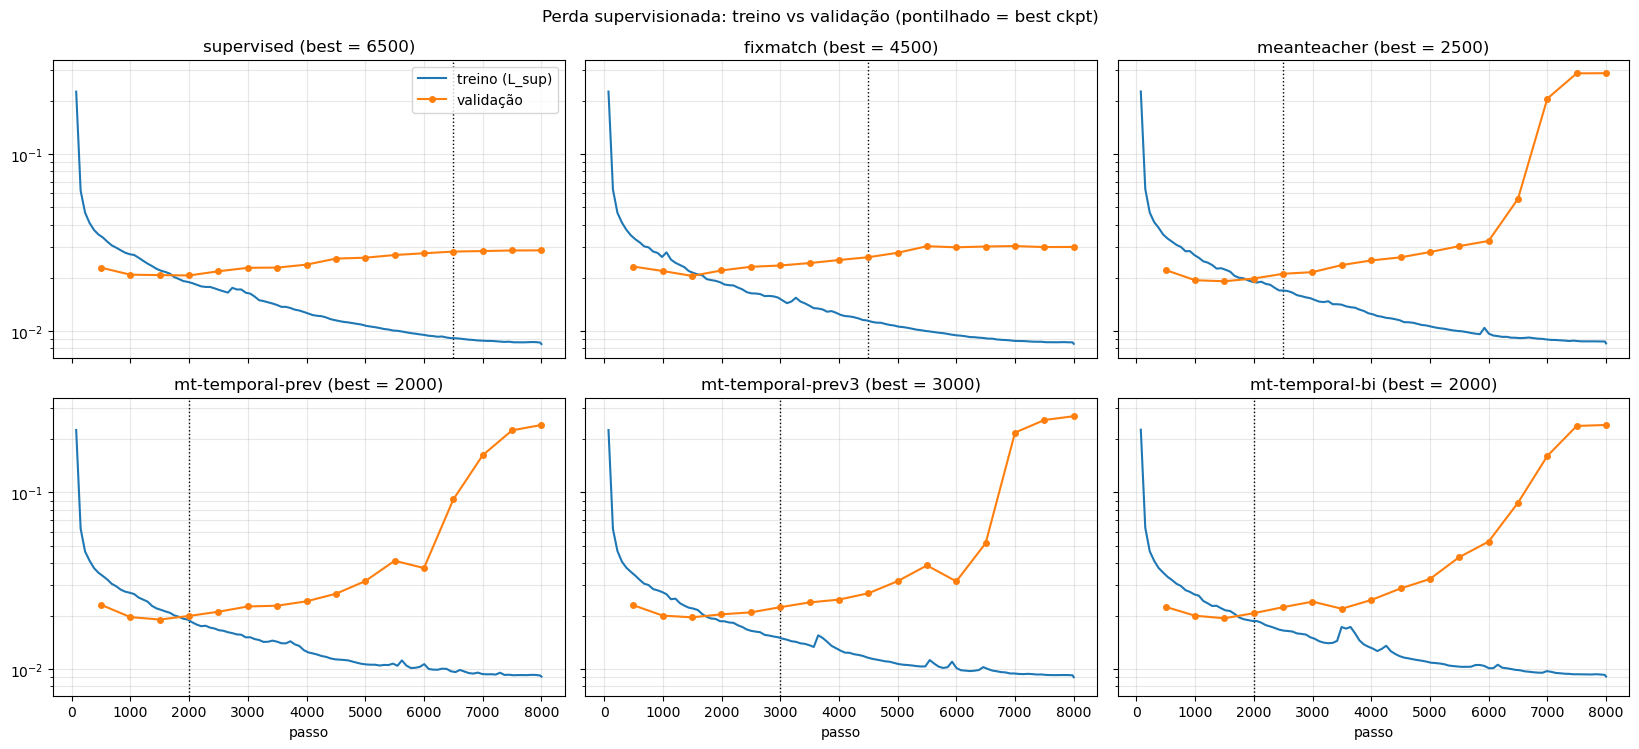

In [31]:
# Mesma funcao de perda nos dois lados: `val/loss` e a perda supervisionada (Dice+CE) da rede avaliada,
# entao o par comparavel e `train/sup_loss`, nao `train/loss` (que inclui os termos nao supervisionados).
fig, axes = method_grid(order, sharey=True)
for ax, method in zip(axes.flat, order):
    t, v = runs[method]["train"], runs[method]["val"]
    ax.plot(t.step, t["train/sup_loss"], label="treino (L_sup)")
    ax.plot(v.step, v["val/loss"], "o-", ms=4, label="validação")
    ax.set_yscale("log")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Perda supervisionada: treino vs validação (pontilhado = best ckpt)")
fig.tight_layout()

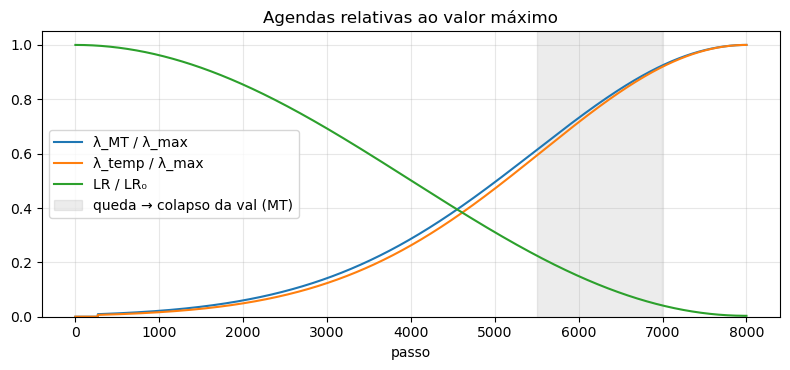

In [39]:
# Agendas (iguais em todos os MT; recalculadas dos YAMLs). Faixa cinza = passos em que a val dos MT colapsou.
s = runs[mt_order[0]]["sched"]
temporal = next((runs[m]["sched"] for m in mt_order if runs[m]["sched"].attrs["lam_temp_max"] > 0), None)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(s.step, s.lam_mt / s.attrs["lam_mt_max"], label="λ_MT / λ_max")
if temporal is not None:
    ax.plot(temporal.step, temporal.lam_temp / temporal.attrs["lam_temp_max"], label="λ_temp / λ_max")
ax.plot(s.step, s.lr_rel, label="LR / LR₀")
drops = [drop_step(runs[m]["val"]) for m in mt_order]
collapses = [collapse_step(runs[m]["val"]) for m in mt_order]
ax.axvspan(min(d for d in drops if d), max(c for c in collapses if c), color="0.5", alpha=0.15,
           label="queda → colapso da val (MT)")
ax.set_xlabel("passo")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("Agendas relativas ao valor máximo")
fig.tight_layout()

In [40]:
rows = []
for method in order:
    r = runs[method]
    v, s = r["val"], r["sched"]
    i_best = int(v["val/dice_patient"].idxmax())
    i_min_loss = int(v["val/loss"].idxmin())
    cs = collapse_step(v)
    row = {
        "method": method,
        "val_dice_max": v["val/dice_patient"].iloc[i_best],
        "passo_max": int(v.step.iloc[i_best]),
        "val_dice_final": v["val/dice_patient"].iloc[-1],
        "passo_min_val_loss": int(v.step.iloc[i_min_loss]),
        "passo_queda": drop_step(v),
        "passo_colapso": cs,
    }
    if cs is not None:
        vc = v[v.step == cs].iloc[0]
        row.update({
            "train_dice@colapso": vc.train_dice_at_val,
            "val_loss@colapso": vc["val/loss"],
            "λ_MT/λmax@colapso": s.lam_mt[cs] / s.attrs["lam_mt_max"] if s.attrs["lam_mt_max"] else np.nan,
            "λ_temp/λmax@colapso": s.lam_temp[cs] / s.attrs["lam_temp_max"] if s.attrs["lam_temp_max"] else np.nan,
            "LR/LR0@colapso": s.lr_rel[cs],
        })
    rows.append(row)
onset = pd.DataFrame(rows).set_index("method")
onset.round(3)

,val_dice_max,passo_max,val_dice_final,passo_min_val_loss,passo_queda,passo_colapso,train_dice@colapso,val_loss@colapso,λ_MT/λmax@colapso,λ_temp/λmax@colapso,LR/LR0@colapso
method,,,,,,,,,,,
supervised,0.845,6499,0.843,1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fixmatch,0.840,4499,0.836,1499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meanteacher,0.850,2499,0.000,1499,6499.0,6999.0,0.963,0.207,0.925,NaN,0.041
mt-temporal-prev,0.848,1999,0.000,1499,5499.0,6499.0,0.960,0.091,0.839,0.828,0.087
mt-temporal-prev3,0.850,2999,0.002,1499,5499.0,6999.0,0.961,0.218,0.925,0.920,0.041
mt-temporal-bi,0.850,1999,0.001,1499,5499.0,6999.0,0.960,0.161,0.925,0.920,0.041


### Decomposição da perda do MT: quem pesou, e por quê

A perda otimizada é $\mathcal L = \mathcal L_{sup} + \lambda_{MT}(s)\,\mathcal L_{MT} + \lambda_{temp}(s)\,\mathcal L_{temp}$.
Para cada termo não supervisionado, a contribuição **relativa ao supervisionado** se fatora em

$$
\underbrace{\frac{\lambda(s)\,\mathcal L(s)}{\mathcal L_{sup}(s)}}_{\text{contribuição}}
= \underbrace{\frac{\lambda(s)}{\lambda_{max}}}_{\text{rampa}}
\times \underbrace{\lambda_{max}}_{\text{teto do peso}}
\times \underbrace{\frac{\mathcal L(s)}{\mathcal L_{sup}(s)}}_{\text{sinal}}
$$

Em escala log as três barras somam o log da contribuição (◆). Rampa ≪ 1 → o termo era pequeno porque a rampa
ainda o segurava; teto ≪ 1 → é pequeno por escolha de $\lambda_{max}$ (0,1 aqui); sinal ≪ 1 → student e teacher
já concordam mais do que o student concorda com o rótulo (sinal fraco). O peso efetivo é rampa × teto.

Ressalvas: (1) magnitude de perda não é magnitude de gradiente (MSE sobre probabilidades vs Dice+CE) — é uma proxy;
(2) $\lambda(s)$ é recalculado, e o $\lambda\mathcal L$ logado é a média por época de $\lambda\cdot\mathcal L$ (o sanity
check acima mostra que a soma fecha); (3) o fator sinal usa as perdas por época divididas — ruidoso no começo.

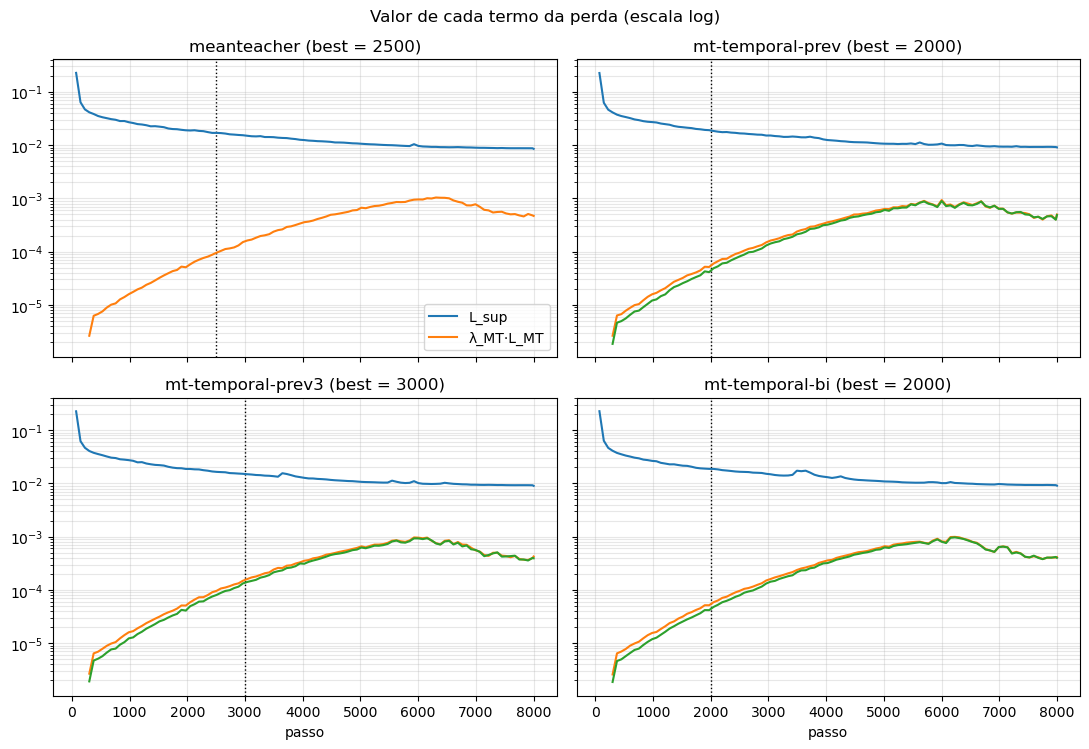

In [41]:
# Valor de cada termo da perda do student (o que de fato foi somado: L_sup + λ·L_MT + λ·L_temp).
TERMS = [("train/sup_loss", "L_sup"),
         ("train/unsup_loss_weighted", "λ_MT·L_MT"),
         ("train/temporal_loss_weighted", "λ_temp·L_temp")]
fig, axes = method_grid(mt_order, ncols=2, sharey=True)
for ax, method in zip(axes.flat, mt_order):
    t = runs[method]["train"]
    for col, lab in TERMS:
        if col in t and t[col].abs().sum() > 0:
            ax.plot(t.step, t[col].where(t[col] > 0), label=lab)
    ax.set_yscale("log")
axes[0, 0].legend(loc="lower right")
fig.suptitle("Valor de cada termo da perda (escala log)")
fig.tight_layout()

% λ·L_MT                                                    \
method meanteacher mt-temporal-bi mt-temporal-prev mt-temporal-prev3   
passo                                                                  
1000          0.06           0.06             0.06              0.06   
2000          0.27           0.27             0.27              0.27   
3000          0.98           0.97             0.97              0.96   
4500          4.10           3.81             4.04              3.78   
6000          9.00           6.93             7.45              7.97   
8000          5.22           4.18             4.95              4.33   

        % λ·L_temp                                                    
method meanteacher mt-temporal-bi mt-temporal-prev mt-temporal-prev3  
passo                                                                 
1000           0.0           0.04             0.04              0.05  
2000           0.0           0.22             0.22              0.22  
3000           0.0           0.85             0.85              0.86  
4500           0.0           3.58             3.65              3.60  
6000           0.0           6.85             7.14              7.72  
8000           0.0           4.05             4.83              4.00

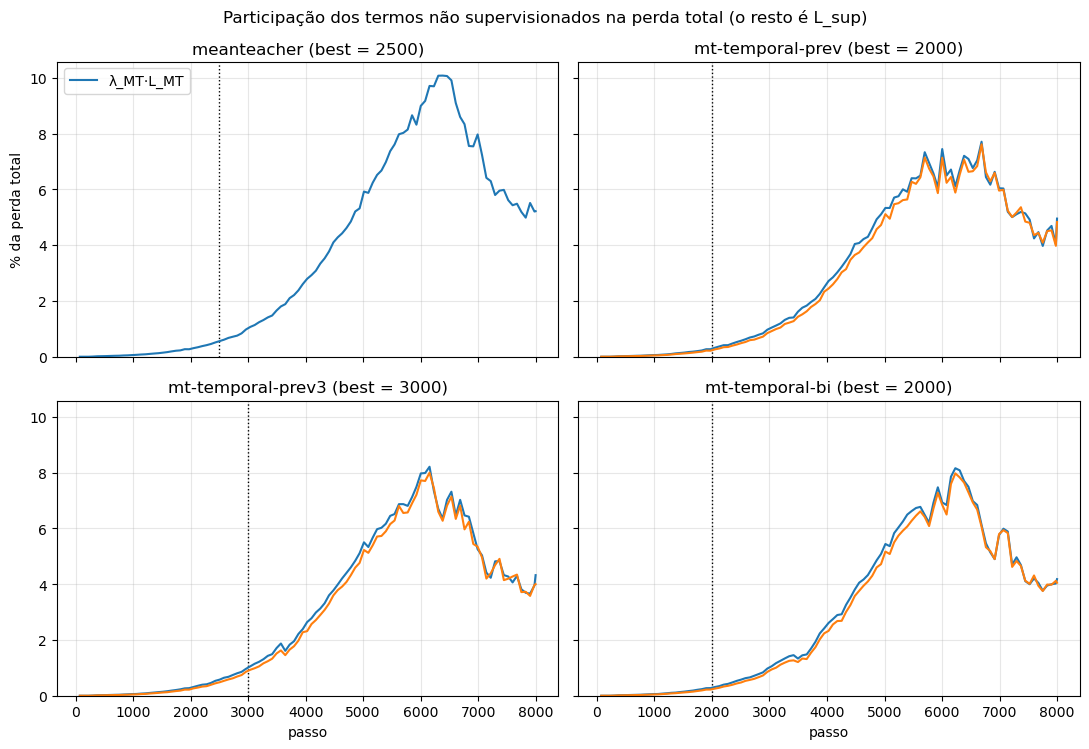

In [42]:
# Quanto cada termo representa do total.
fig, axes = method_grid(mt_order, ncols=2, sharey=True)
for ax, method in zip(axes.flat, mt_order):
    t = runs[method]["train"]
    for col, lab in TERMS[1:]:
        if col in t and t[col].abs().sum() > 0:
            ax.plot(t.step, 100 * t[col] / t["train/loss"], label=lab)
    ax.set_ylim(bottom=0)
axes[0, 0].set_ylabel("% da perda total")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Participação dos termos não supervisionados na perda total (o resto é L_sup)")
fig.tight_layout()

share_rows = []
for method in mt_order:
    t = runs[method]["train"]
    for step in [1000, 2000, 3000, 4500, 6000, 8000]:
        e = t.iloc[(t.step - step).abs().idxmin()]
        share_rows.append({"method": method, "passo": step,
                           "% λ·L_MT": 100 * e["train/unsup_loss_weighted"] / e["train/loss"],
                           "% λ·L_temp": 100 * e.get("train/temporal_loss_weighted", 0.0) / e["train/loss"]})
pd.DataFrame(share_rows).pivot(index="passo", columns="method").round(2)

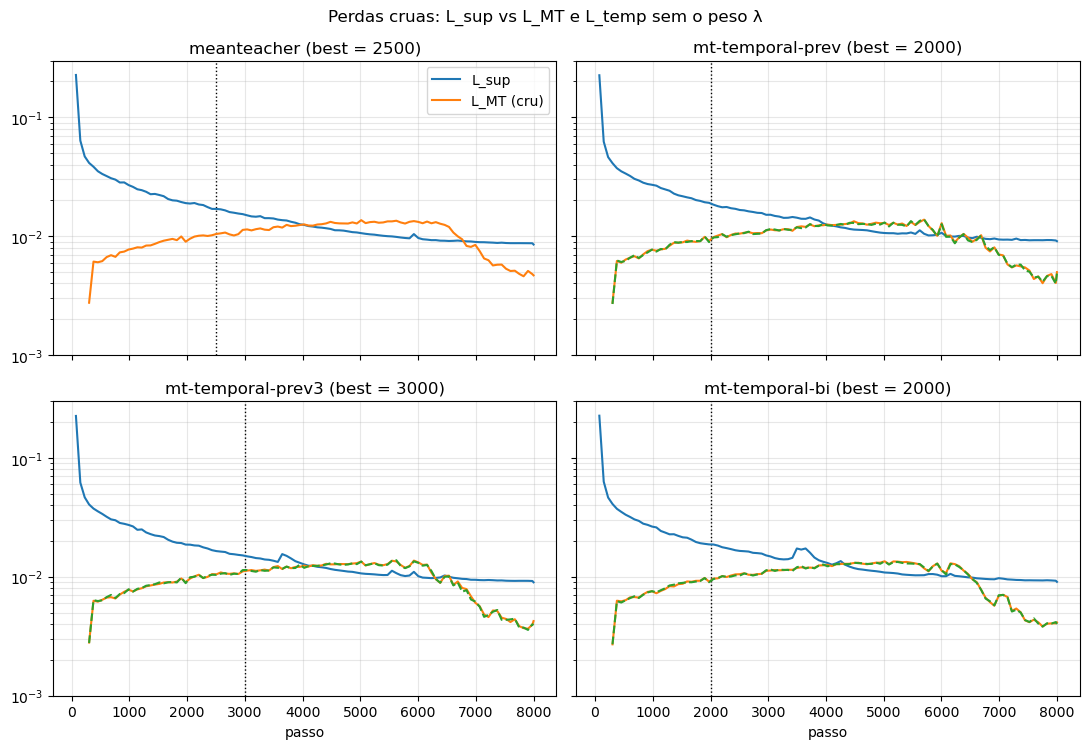

In [36]:
# Sinal: perdas CRUAS (antes do λ). Se L_MT cru ~ L_sup, o termo nao e fraco; e o peso que o deixa pequeno.
fig, axes = method_grid(mt_order, ncols=2, sharey=True)
for ax, method in zip(axes.flat, mt_order):
    t = runs[method]["train"]
    ax.plot(t.step, t["train/sup_loss"], label="L_sup")
    ax.plot(t.step, t["train/unsup_loss"].where(t["train/unsup_loss"] > 0), label="L_MT (cru)")
    if "train/temporal_loss" in t and t["train/temporal_loss"].abs().sum() > 0:
        ax.plot(t.step, t["train/temporal_loss"].where(t["train/temporal_loss"] > 0), "--", label="L_temp (cru)")
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 0.3)
axes[0, 0].legend(loc="upper right")
fig.suptitle("Perdas cruas: L_sup vs L_MT e L_temp sem o peso λ")
fig.tight_layout()

rampa  teto   sinal  contrib
method            termo passo                               
meanteacher       mt    1000   0.0214   0.1  0.2870   0.0006
                        2000   0.0587   0.1  0.4737   0.0028
                        3000   0.1378   0.1  0.7370   0.0102
                        4500   0.3805   0.1  1.1471   0.0436
                        6000   0.7323   0.1  1.3663   0.1001
                        8000   1.0000   0.1  0.5506   0.0551
mt-temporal-prev  mt    1000   0.0214   0.1  0.2843   0.0006
                        2000   0.0587   0.1  0.4771   0.0028
                        3000   0.1378   0.1  0.7380   0.0102
                        4500   0.3805   0.1  1.1753   0.0447
                        6000   0.7323   0.1  1.2060   0.0883
                        8000   1.0000   0.1  0.5492   0.0549
                  temp  1000   0.0164   0.1  0.2851   0.0005
                        2000   0.0481   0.1  0.4672   0.0022
                        3000   0.1199   0.1  0.7424   0.0089
                        4500   0.3556   0.1  1.1371   0.0404
                        6000   0.7165   0.1  1.1822   0.0847
                        8000   1.0000   0.1  0.5358   0.0536
mt-temporal-prev3 mt    1000   0.0214   0.1  0.2851   0.0006
                        2000   0.0587   0.1  0.4820   0.0028
                        3000   0.1378   0.1  0.7341   0.0101
                        4500   0.3805   0.1  1.0945   0.0416
                        6000   0.7323   0.1  1.3070   0.0957
                        8000   1.0000   0.1  0.4718   0.0472
                  temp  1000   0.0164   0.1  0.2876   0.0005
                        2000   0.0481   0.1  0.4736   0.0023
                        3000   0.1199   0.1  0.7528   0.0090
                        4500   0.3556   0.1  1.1170   0.0397
                        6000   0.7165   0.1  1.2951   0.0928
                        8000   1.0000   0.1  0.4366   0.0437
mt-temporal-bi    mt    1000   0.0214   0.1  0.2856   0.0006
                        2000   0.0587   0.1  0.4858   0.0028
                        3000   0.1378   0.1  0.7417   0.0102
                        4500   0.3805   0.1  1.1035   0.0420
                        6000   0.7323   0.1  1.1113   0.0814
                        8000   1.0000   0.1  0.4558   0.0456
                  temp  1000   0.0164   0.1  0.2863   0.0005
                        2000   0.0481   0.1  0.4808   0.0023
                        3000   0.1199   0.1  0.7493   0.0090
                        4500   0.3556   0.1  1.1111   0.0395
                        6000   0.7165   0.1  1.1225   0.0804
                        8000   1.0000   0.1  0.4416   0.0442

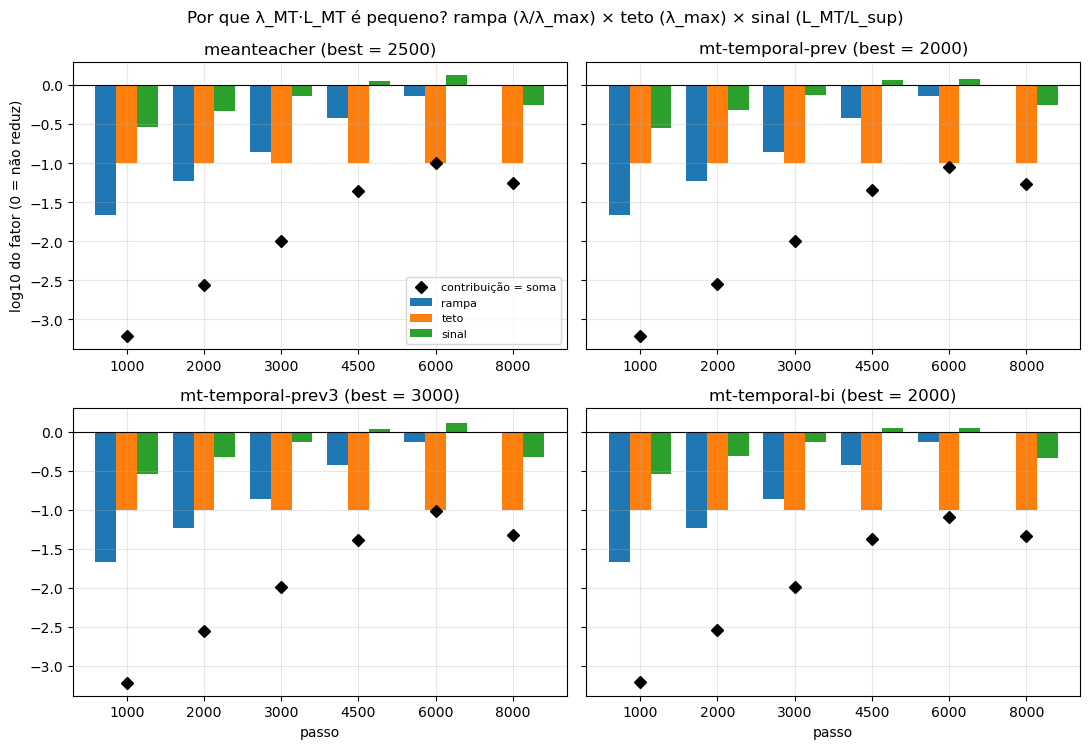

In [37]:
# Fatoracao λ(s)·L(s)/L_sup = rampa × teto × sinal, no termo MT (o temporal tem numeros quase iguais: tabela).
PROBE_STEPS = [1000, 2000, 3000, 4500, 6000, 8000]
UNSUP = [("mt", "train/unsup_loss", "lam_mt"), ("temp", "train/temporal_loss", "lam_temp")]
factor_rows = []
for method in mt_order:
    t, s = runs[method]["train"], runs[method]["sched"]
    for name, col, lam in UNSUP:
        lam_max = s.attrs[f"{lam}_max"]
        if col not in t or lam_max == 0:
            continue
        for step in PROBE_STEPS:
            e = t.iloc[(t.step - step).abs().idxmin()]
            ramp = s[lam][int(e.step)] / lam_max
            signal = e[col] / e["train/sup_loss"]
            factor_rows.append({"method": method, "termo": name, "passo": step, "rampa": ramp,
                                "teto": lam_max, "sinal": signal, "contrib": ramp * lam_max * signal})
factors = pd.DataFrame(factor_rows)

fig, axes = method_grid(mt_order, ncols=2, best_line=False, sharey=True, sharex=False)
x = np.arange(len(PROBE_STEPS))
w = 0.27
for ax, method in zip(axes.flat, mt_order):
    f = factors[(factors.method == method) & (factors.termo == "mt")]
    for i, key in enumerate(["rampa", "teto", "sinal"]):
        ax.bar(x + (i - 1) * w, np.log10(f[key]), w, label=key)
    ax.plot(x, np.log10(f["contrib"]), "kD", label="contribuição = soma")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x, PROBE_STEPS)
axes[0, 0].set_ylabel("log10 do fator (0 = não reduz)")
axes[0, 0].legend(loc="lower right", fontsize=8)
fig.suptitle("Por que λ_MT·L_MT é pequeno? rampa (λ/λ_max) × teto (λ_max) × sinal (L_MT/L_sup)")
fig.tight_layout()
factors.set_index(["method", "termo", "passo"]).round(4)

### Leitura (seed 42, DeepLabV3+) e como seguir

Números das tabelas acima (uma seed; tratar como indício, não como resultado):

1. **O que colapsa é a val do teacher, não o treino.** O Dice de treino do student (train mode) fica em ~0,96 do
   passo ~5000 até o fim em todas as runs MT, enquanto `val/dice_patient` começa a cair no passo **5500**
   (`mt-temporal-*`) ou **6500** (`meanteacher`), passa de 50% do máximo em **6500–7000** e chega a ~0 em 7500–8000.
   Nos controles (`supervised`, `fixmatch`) o gap treino–val fica estável em ~0,12. A perda de treino não colapsa
   (só tem picos isolados nos temporais perto do passo 3500).
2. **`val/loss` antecipa o problema.** O mínimo de `val/loss` é no passo 1500–2000 em **todas** as runs (leve overfit
   comum a todas), mas nos MT ela se descola dos controles a partir de ~4500–5000 e explode depois de 6000. O best
   ckpt dos MT (2000–3000) fica muito antes disso.
3. **Quem domina a perda: o supervisionado, sempre.** λ·L_MT é ≤ 1% do total até o passo 3000, ~4% em 4500 e
   atinge o pico perto de 6000 (~9% no `meanteacher`; ~15% somando MT + temporal nos `mt-temporal-*`), caindo para
   5–9% no passo 8000.
4. **Pequeno pelo peso, não pelo sinal.** O L_MT cru **não é fraco**: L_MT/L_sup sobe de ~0,29 (passo 1000) para
   ~0,74 (3000) e fica em 1,1–1,4 em 4500–6000, ou seja, o termo cru é do tamanho do supervisionado. A contribuição
   pequena vem do peso: a rampa (0,02–0,14 até o passo 3000) vezes o teto λ_max = 0,1. **No best ckpt (2000–3000) a
   consistência pesa 0,3–1% do supervisionado** → o ganho do MT nesse ponto dificilmente vem do termo de
   consistência; o candidato é o teacher EMA como avaliador (testar com a D1).
5. **Termo temporal ≈ termo MT.** L_temp cru e L_MT cru andam quase juntos em toda a run (mesma ordem até a 3ª casa).
   Ou o alvo transportado é praticamente a mesma previsão do teacher no frame central (vizinhos próximos, fluxo pequeno),
   ou o termo temporal acrescenta pouco além de dobrar o peso da consistência. Vale medir a diferença entre os dois
   alvos diretamente.
6. **Quando colapsa, tudo está no extremo ao mesmo tempo**: rampa em 0,84–0,93, LR em 4–9% do LR₀, contribuição
   da consistência perto do pico. Como λ, LR e passo são monótonos, estas runs não separam as três causas. Um
   indício fraco a favor do peso: os temporais (dois termos de 0,1, peso não supervisionado efetivo dobrado) começam
   a cair ~1000 passos antes do `meanteacher`. O L_MT cru cai depois de ~6500 junto com o colapso: student e teacher
   passam a concordar mais exatamente quando o teacher em eval deixa de prever o primeiro plano. Isso é compatível
   com os dois convergindo para uma solução degenerada, ou com o teacher acompanhando o student quando o LR fica
   pequeno; a `probe/fg_frac_*` da D0 distingue.

#### Próximos passos — bateria já preparada (`scripts/e2_diag.py`, saídas em `logs/e2-diag/runs/`)

Cada run é o `meanteacher` do E2 com **uma** mudança, com a sonda `MTEvalProbe` (`src/callbacks.py`), snapshots a
cada 1000 passos e sem olhar o teste INCA. Ordem sugerida, como árvore de decisão:

1. **D0 — reproduz com a sonda** (`python scripts/e2_diag.py run D0`). Comparar `probe/dice_teacher_eval`
   (= a val atual), `probe/dice_student_eval`, `probe/dice_teacher_bnrecal` e `probe/dice_teacher_trainbn`:
   - student em eval e teacher recalibrado **bons**, teacher em eval ruim → o problema é a avaliação do teacher
     (pesos EMA + running stats copiados do student). Correção candidata: `bn_buffer_mode: ema` ou `recalibrate`
     (já implementados em `src/models/ssl/mean_teacher.py`); conferir `probe/bn_var_*`, `probe/param_dist`.
   - student em eval **também** cai → os pesos pioraram de fato; ir para 2–4.
   - `probe/fg_frac_teacher` → 0 com `fg_frac_gt` constante indica colapso para "tudo fundo";
     `probe/fg_frac_unl_*` diz se o mesmo acontece nos não rotulados (alvo do teacher degenerado realimentando o student).
   - `probe/train_dice_eval_*`: gap treino–val medido no **mesmo** modo eval — separa overfit de artefato de modo.
2. **D1 — λ = 0** (supervisionado + teacher EMA como avaliador). Colapsa mesmo assim → a consistência não é a causa
   (sobra EMA/BN/overfit) e o ganho do MT no best ckpt vem do EMA, não do termo. Não colapsa → o termo importa:
   **D2** (rampa até 50% do orçamento: colapso deve chegar antes) e **D3** (λ = 1: deve chegar antes/mais fundo).
3. **D4 — LR ~constante**: o colapso acompanha o cosseno do LR ou só o número de passos?
4. **D5–D7 — augmentation** no student/teacher, pacote anti-overfit (aug + λ 0,03 + EMA 0,999) e o controle
   supervisionado com aug: se o mecanismo for overfit do conjunto rotulado (train Dice → 0,96, `val/loss` subindo).
5. **Instrumentação que ainda falta**: norma do gradiente por termo no student (tira a ressalva "perda ≠ gradiente"
   da decomposição acima) e λ por passo no CSV (`*_weight_step` sai vazio; checar `log_every_n_steps`).

Re-runs idênticos já divergiram até ~0,10 Dice no X1: as conclusões de dose-resposta (D2/D3) e de qualquer variante
que "conserte" o colapso precisam de ≥ 2 seeds antes de entrar no texto.

In [38]:
# preciso checar:
# - porque todos os mean teacher tiveram deterioracao no final do treino?
# - qual o impacto da loss temporal?
# - quais os resultados qualitativos? Deveria usar alguma metrica de estabilidade temporal?
# - Deveria comparar com o proprio DTC-TRUS?
